# Strip waveguide - width sweep

This notebook contains code that conduct mode analysis of strip waveguide using **Tid3d**. \
It does width sweep of the waveguide core and tracks moodes effective indices. \
The objective is to find the maximum waveguide width that supports single-mode operation.

In [36]:
%%capture

# Install dependencies specified in pyproject.toml
!uv pip install --reinstall --refresh -r pyproject.toml

# Enable interactive Matplotlib plots
%matplotlib widget

# Import modules
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import photonix as px
import tidy3d as td
from tidy3d.plugins.dispersion import FastDispersionFitter
from tidy3d.plugins.mode import ModeSolver

In [37]:
# Tidy3d version
print(f"Tidy3d version: {td.__version__}")

Tidy3d version: 2.12.2


In [38]:
%%html

<!-- Align table to the left -->
<style>
  table {margin-left: 0 !important;}
</style>

In [39]:
# Constants

um = 1e-6
nm = 1e-9
c = 299792458

# Simulation input

| Parameter                 | Description                                                                                   | Example                |
| :------------------------ | :-------------------------------------------------------------------------------------------- | :--------------------- |
| **wavelength_center**     | Wavelength for which simulation will be done. (i)                                             | `1.55*um`              |
| **core_thickness**        | Thickness of the burried oxide strip waveguide core.                                          | `220*nm`               |
| **core material**         | Material of strip waveguide core as defined in materials library of specified solver backend. | `Si (Silicon) - Palik` |
| **clad material**         | Material of strip waveguide clad as defined in materials library of specified solver backend. | `SiO2 (Glass) - Palik` |

In [59]:
# Si/SiO2/Si ????x220nm 1550nm

width_sweep = np.arange(50*nm, 2000*nm, 10*nm)

wavelength_center = 1.55*um
core_thickness = 220*nm

bottom_clad_thickness = 3*um
top_clad_thickness = 2*um

# https://docs.flexcompute.com/projects/tidy3d/en/stable/api/material_library.html
core_material = "cSi Palik_LowLoss"
clad_material = "SiO2 Palik_LowLoss"
substrate_material = "cSi Palik_LowLoss"

In [60]:
# Si3N4/SiO2/Si ????x360nm 1550nm

width_sweep = np.arange(50*nm, 2000*nm, 10*nm)

wavelength_center = 1.55*um
core_thickness = 360*nm

bottom_clad_thickness = 5*um
top_clad_thickness = 5*um

# https://docs.flexcompute.com/projects/tidy3d/en/stable/api/material_library.html
core_material = "Si3N4 Luke2015PMLStable"
clad_material = "SiO2 Palik_LowLoss"
substrate_material = "cSi Palik_LowLoss"

In [61]:
field_intensity_log_decay = -6
initial_core_width = max(width_sweep)
initial_fde_width = 3 * initial_core_width
initial_fde_height = 12 * core_thickness
min_steps_per_wvl = 20

In [62]:
frequency_center = (td.C_0*1e-6)/ wavelength_center

In [63]:
# Materials fitting

# Helper to fit materials
def fit_material(material_name):
    material_name, material_model = material_name.split()
    material = td.material_library[material_name][material_model]

    # TODO: Check fitting !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
    return material
    
    wavelength_min = wavelength_center - 150*nm
    wavelength_max = wavelength_center + 150*nm
    wavelengths = np.linspace(wavelength_min, wavelength_max, 50)
    freqs = (td.C_0 * 1e-6)/wavelengths

    eps = np.array([material.eps_model(f) for f in freqs])
    n, k = np.real(np.sqrt(eps)), np.imag(np.sqrt(eps))
    fitter = FastDispersionFitter(
      wvl_um=wavelengths*1e6, n_data=n, k_data=k, wvl_range=(wavelength_min*1e6, wavelength_min*1e6)
    )
    fitted, _ = fitter.fit(min_num_poles=1, max_num_poles=6, tolerance_rms=0.001)
    return fitted

core_material = fit_material(core_material)
clad_material = fit_material(clad_material)
substrate_material = fit_material(substrate_material)

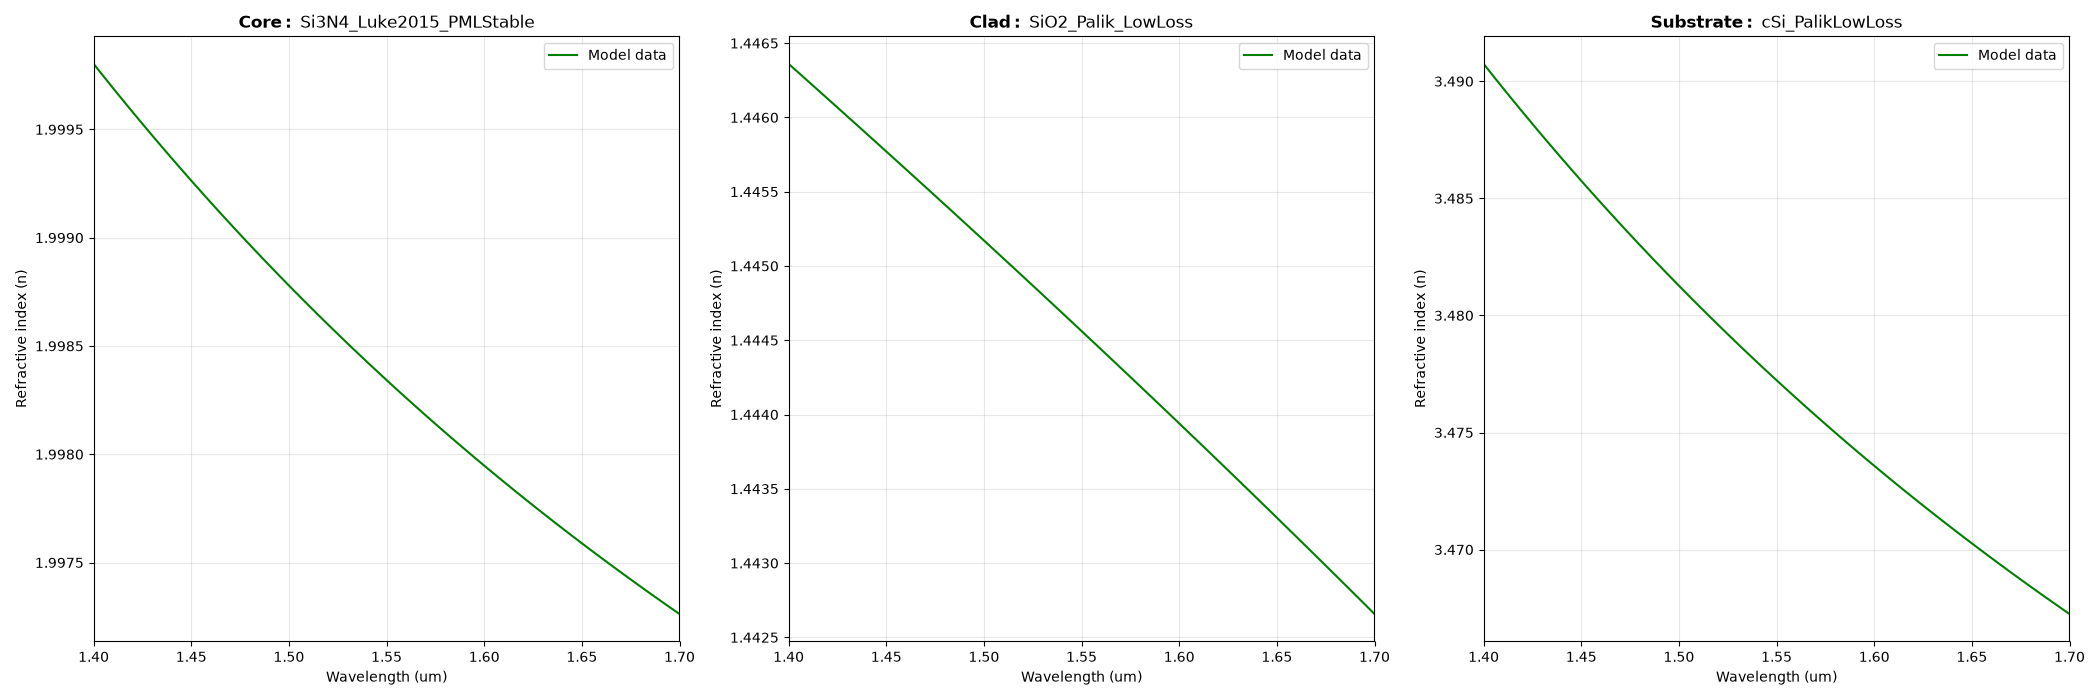

In [64]:
# Materials fit preview

def plot_material(material, ax):
    # ax.set_title(material)

    wvl_min = wavelength_center - 150 * nm
    wvl_max = wavelength_center + 150 * nm
    f1 = (td.C_0 * 1e-6) / np.linspace(wvl_min, wvl_max, 100)

    eps = np.array([material.eps_model(f) for f in f1])
    mat_n_model, mat_k_model = np.real(np.sqrt(eps)), np.imag(np.sqrt(eps))

    mat_n_model = np.column_stack((f1, mat_n_model))

    px.plot_material_n(
        mat_n_model=mat_n_model,
        wavelength_min=wvl_min, wavelength_max=wvl_max,
        ax=ax
    )
    ax.ticklabel_format(axis='y', useOffset=False, style='plain')
    

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21, 7))

# Core
plot_material(core_material, ax1)
ax1.set_title(f"$\\bf{{Core:}}$ {core_material.name}")

# Clad
plot_material(clad_material, ax2)
ax2.set_title(f"$\\bf{{Clad:}}$ {clad_material.name}")

# Substrate
plot_material(substrate_material, ax3)
ax3.set_title(f"$\\bf{{Substrate:}}$ {substrate_material.name}")

fig.tight_layout()
plt.show()

In [65]:
# Structure geometry

# tidy3d is operating with um
core_thickness_um = core_thickness*1e6
initial_core_width_um = initial_core_width*1e6
bottom_clad_thickness_um = bottom_clad_thickness*1e6
top_clad_thickness_um = top_clad_thickness*1e6

clad_thickness_um = bottom_clad_thickness_um + core_thickness_um + top_clad_thickness_um
clad_center_z_um = (top_clad_thickness_um - bottom_clad_thickness_um) / 2

substrate_thickness_um = 100
substrate_z_max = clad_center_z_um - clad_thickness_um/2
substrate_z_min = substrate_z_max - substrate_thickness_um

# Substrate
substrate = td.Structure(
    name="substrate",
    geometry=td.Box.from_bounds(
        rmax=(td.inf, 0.5, substrate_z_max),
        rmin=(-td.inf, -0.5, substrate_z_min),
    ),
    medium=substrate_material
)

# Clad

clad = td.Structure(
    name="clad",
    geometry=td.Box(
        center=(0, 0, clad_center_z_um),
        size=(td.inf, 1, clad_thickness_um)
    ),
    medium=clad_material
)

# Core
core = td.Structure(
    name="core",
    geometry=td.Box(
        center=(0, 0, 0),
        size=(initial_core_width_um, 1, core_thickness_um)
    ),
    medium=core_material
)

In [66]:
# Simulation setup

# Grid
min_steps_per_wvl=20

# For substrate apply 2x coarser mesh than in clad
clad_n, _ = clad_material.nk_model(frequency_center)
sdl_um = 2*px.calc_grid_dl(wavelength_center, clad_n, min_steps_per_wvl)*1e6

substrate_mesh_override = td.MeshOverrideStructure(
    geometry=substrate.geometry,
    dl=(sdl_um, sdl_um, sdl_um)
)

grid = td.GridSpec.auto(
    wavelength=1.55,
    min_steps_per_wvl=min_steps_per_wvl,
    override_structures=[substrate_mesh_override]
)

# Boundaries
boundaries = td.BoundarySpec.pec(x=True, y=True, z=True)

# XZ plane
plane = td.Box(
    center=(0, 0, 0), 
    size=(td.inf, 0, td.inf)
)

initial_fde_width_um = initial_fde_width*1e6
initial_fde_height_um = initial_fde_height*1e6
sim = td.Simulation(
    size=(initial_fde_width_um, 0.1, initial_fde_height_um),
    boundary_spec=boundaries,
    grid_spec=grid,
    structures=[substrate, clad, core],
    run_time=3e-13,
)

# Mode solver
sort_spec=td.ModeSortSpec(
    sort_key="fill_fraction_box",
    bounding_box=core.geometry,
)

mode_spec=td.ModeSpec(
    num_modes=4,
    precision="double",
    num_pml=(12, 12),
    sort_spec=sort_spec,
)

mode_solver = ModeSolver(
    freqs=[frequency_center],
    plane=plane,
    simulation=sim,
    mode_spec=mode_spec,
)



19:50:04 UTC WARNING: 'substrate' (simulation.structures[0]) is outside of the  
             simulation domain.                                                 

             WARNING: 'substrate' (simulation.structures[0]) is outside of the  
             simulation domain.                                                 

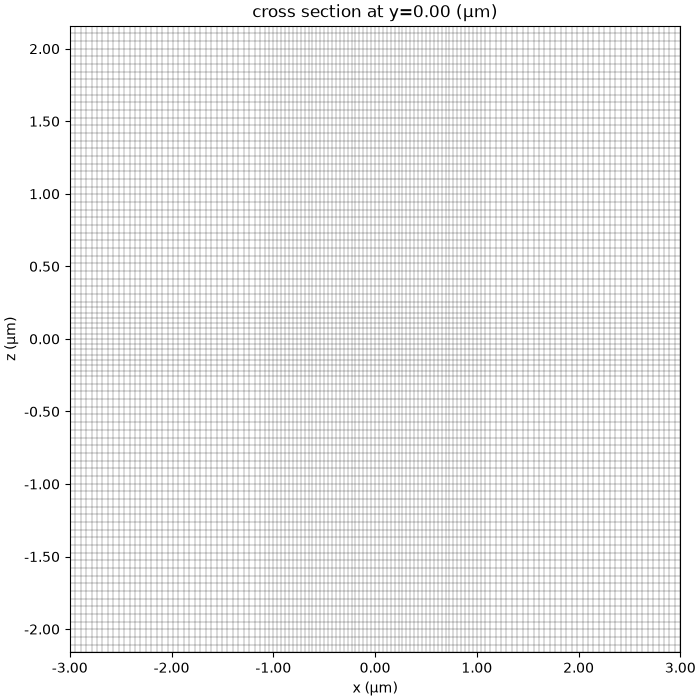

In [67]:
# Simulation preview

fig, ax = plt.subplots(1, 1, figsize=(7, 7), constrained_layout=True)

# Grid
sim.plot_grid(y=0, ax=ax)
plt.show()

# Structure
sim.plot_3d()

wavelength     n eff         k eff  loss (dB/cm)  \
f            mode_index                                                     
1.934145e+14 0                 1.55  1.688290  1.084291e-08      0.003818   
             1                 1.55  1.589971  1.833696e-08      0.006456   
             2                 1.55  1.587270  4.334858e-07      0.152629   
             3                 1.55  1.509546  2.109281e-06      0.742672   

                         TE (Ex) fraction  wg TE fraction  wg TM fraction  \
f            mode_index                                                     
1.934145e+14 0                   0.999423        0.967231        0.880217   
             1                   0.950736        0.881575        0.898698   
             2                   0.046043        0.855462        0.970081   
             3                   0.015845        0.884202        0.908953   

                         mode area  
f            mode_index             
1.934145e+14 0            1.103092  
             1            1.521513  
             2            1.970628  
             3            2.360380

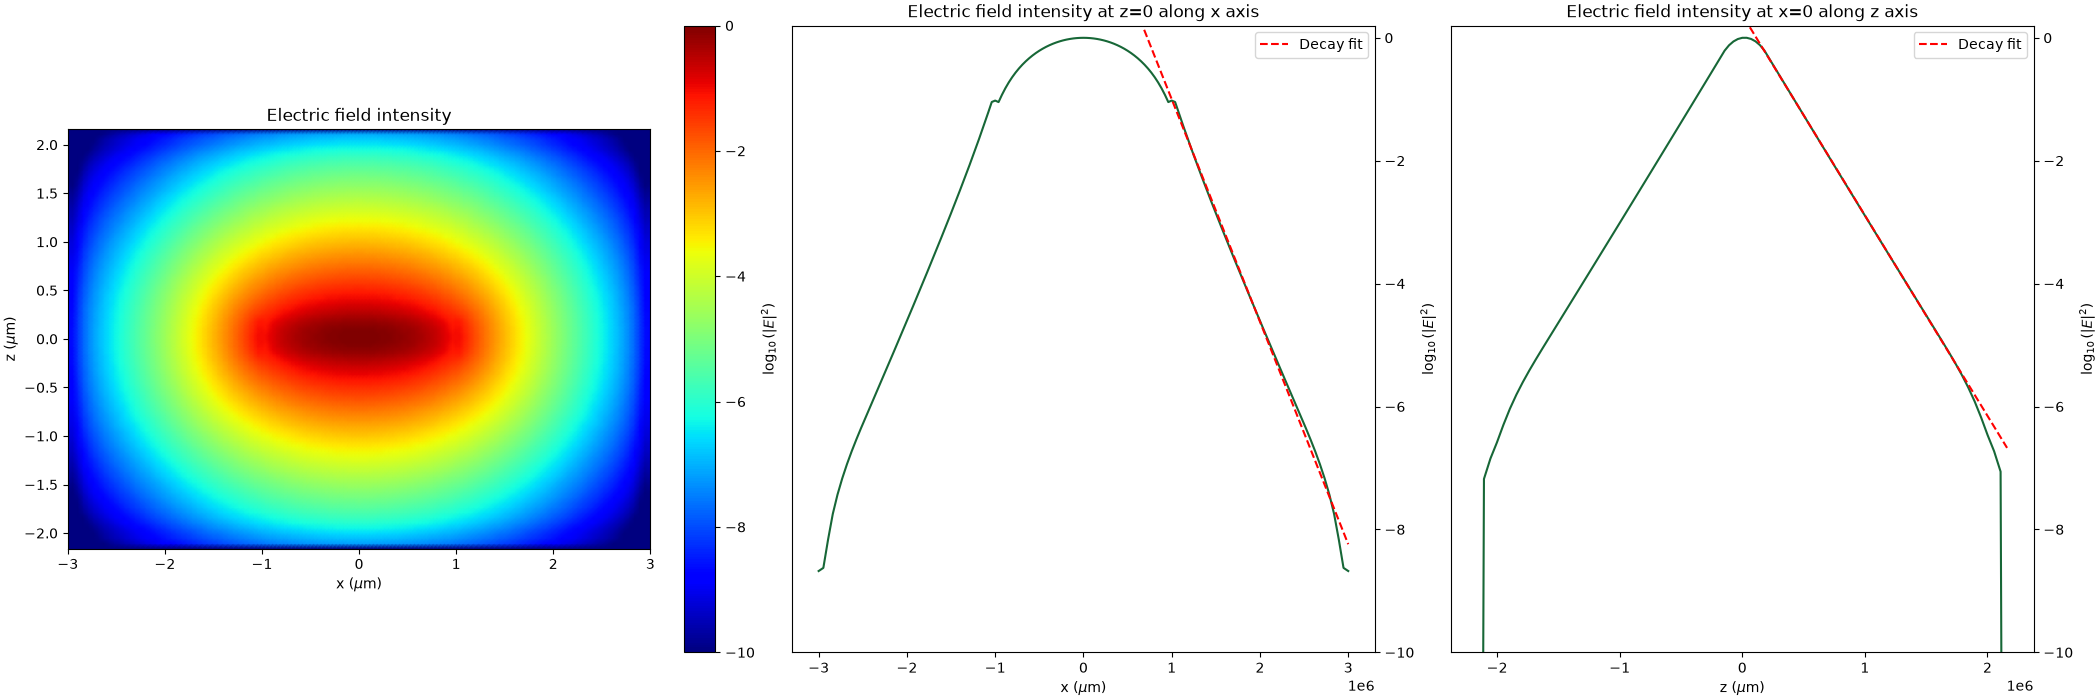

In [68]:
# Initial simulation

mode_data = mode_solver.solve()
mode_df = mode_data.to_dataframe()
display(mode_df)

Ex, Ey, Ez = (getattr(mode_data, c).isel(mode_index=0, f=0) for c in ["Ex", "Ey", "Ez"])
x, z = mode_data.Ex.x, mode_data.Ex.z

decay = px.get_field_decay(Ex, Ey, Ez, margin=3)
confinement = px.get_field_confinement(Ex, Ey, Ez, x=x, z=z, radius=initial_core_width)

xmin = initial_core_width_um/2
xmax = (initial_fde_width_um/2)*0.75
slope_xp, intercept_xp = px.get_decay_slope(
    Ex, Ey, Ez, 
    x=x, 
    amin=xmin,
    amax=xmax,
)

zmin = core_thickness_um/2
zmax = (initial_fde_height_um/2)*0.75
slope_zp, intercept_zp = px.get_decay_slope(
    Ex, Ey, Ez, 
    z=z, 
    amin=zmin,
    amax=zmax,
)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21, 7), constrained_layout=True)

# Efield
px.plot_field(
    Ex, Ey, Ez, 
    x=x, z=z,
    vmin=-10, vmax=0,
    ax=ax1
)
ax1.set_title('Electric field intensity')

# X decay
Eslice_x = px.get_field_intensisty_slice(
    Ex, Ey, Ez,
    x=x,
    scale="log"
)
ax2.plot(x*1e6, Eslice_x)
ax2.set_title('Electric field intensity at z=0 along x axis')
ax2.set_xlabel(r'x ($\mu$m)')
ax2.set_ylabel(r'$\log_{10}(|E|^2)$')
ax2.yaxis.tick_right()
ax2.yaxis.set_label_position("right")
ax2.set_ylim(-10, 0.2)

# X Decay fit
y = slope_xp * x + intercept_xp
ax2.plot(
    x*1e6, y,
    color='red', 
    linestyle='--', 
    linewidth=1.5, 
    label=f'Decay fit'
)
ax2.legend(loc='upper right')

# Z decay
Eslice_z = px.get_field_intensisty_slice(
    Ex, Ey, Ez,
    z=z,
    scale="log"
)
ax3.plot(z*1e6, Eslice_z)
ax3.set_title('Electric field intensity at x=0 along z axis')
ax3.set_xlabel(r'z ($\mu$m)')
ax3.set_ylabel(r'$\log_{10}(|E|^2)$')
ax3.yaxis.tick_right()
ax3.yaxis.set_label_position("right")
ax3.set_ylim(-10, 0.2)

# Z Decay fit
y = slope_zp * z + intercept_zp
ax3.plot(
    z*1e6, y,
    color='red', 
    linestyle='--', 
    linewidth=1.5, 
    label=f'Decay fit'
)
ax3.legend(loc='upper right')

plt.show()

In [139]:
# Calculate FDE width

def update_solver_width(mode_solver, fde_width_um):
    print(f"New fde width: {fde_width_um}")
    mode_solver = mode_solver.updated_copy(
        simulation = sim.updated_copy(
            size=(fde_width_um, sim.size[1], sim.size[2])
        )
    )

    return mode_solver

def ensure_solver_decay(mode_data, mode_solver, target_decay):
    Ex, Ey, Ez = (getattr(mode_data, c).isel(mode_index=0, f=0) for c in ["Ex", "Ey", "Ez"])
    x, z = mode_data.Ex.x, mode_data.Ex.z

    old_fde_width_um = mode_solver.simulation.size[0]
    
    # Right X side
    slope_xp, intercept_xp = px.get_decay_slope(
        Ex, Ey, Ez, 
        x=x, 
        amin=core_width_um/2,
        amax=old_fde_width_um/2,
    )
    # Left X side
    slope_xm, intercept_xm = px.get_decay_slope(
        Ex, Ey, Ez,
        x=x,
        amin=-old_fde_width_um/2,
        amax=-core_width_um/2,
    )

    slope = min(abs(slope_xp), abs(slope_xm))
    intercept = min(intercept_xp, intercept_xm)

    x_target = (target_decay - intercept) / slope
    predicted_fde_width_um = abs(x_target) * 2

    new_fde_width_um = max(old_fde_width_um, predicted_fde_width_um)*1.1
    return update_solver_width(mode_solver, new_fde_width_um)

# Update width
mode_solver = ensure_solver_decay(mode_data, mode_solver, field_intensity_log_decay)

NameError: name 'core_width_um' is not defined

In [ ]:
# Rerun simulation with new FDE width

mode_data = mode_solver.solve()
mode_df = mode_data.to_dataframe()
display(mode_df)

Ex, Ey, Ez = (getattr(mode_data, c).isel(mode_index=0, f=0) for c in ["Ex", "Ey", "Ez"])
x, z = mode_data.Ex.x, mode_data.Ex.z

fig = px.plot_field(
    Ex, Ey, Ez, 
    x=x, z=z,
    vmin=-10, vmax=0,
)
plt.show()

decay = px.get_field_decay(Ex, Ey, Ez, margin=12)
confinement = px.get_field_confinement(Ex, Ey, Ez, x=x, z=z, radius=core_width_um)

print(f"Field decay: {decay}")
print(f"Relative confinement: {confinement}")
last_neff = mode_data.n_eff.sel(mode_index=0).item()

In [ ]:
def update_solver(old_mode_solver, radius_um, target_neff):
    print(f"Solver radius: {radius_um:.1f}, Target neff: {target_neff:.6f}")

    new_mode_solver = old_mode_solver.updated_copy(
        mode_spec = old_mode_solver.mode_spec.updated_copy(
            bend_radius=radius_um,
            target_neff=target_neff,
            bend_axis=1,
        )
    )

    return new_mode_solver

radius_data = {
    "radius": [],
    "neff": [],
    "f": [],
    "loss": [],
    "ng": [],
    "TE polarization fraction": [],
    "waveguide TE/TM fraction": [],
    "mode effective area": [],
    "Efield": [],
    "Hfield": [],
    "power coupling": []
}

decay = 0
# Start from biggest radii
radius_sweep = np.sort(radius_sweep)[::-1]
for r, radius in enumerate(radius_sweep):
    radius_um = radius*1e6
    print(f"---------------- Calculating for radius: {radius_um:.1f} µm ----------------")

    mode_solver = update_solver(mode_solver, radius_um, last_neff)
    mode_data = mode_solver.solve()
    
    Ex, Ey, Ez = (getattr(mode_data, c).isel(mode_index=0, f=0) for c in ["Ex", "Ey", "Ez"])
    decay = px.get_field_decay(Ex, Ey, Ez, margin=12)
    print(f"Field decay: {decay}")

    while decay > field_intensity_log_decay:
        print(f"---------------- Optimizing decay: {decay:.2f} ----------------")
        mode_solver = ensure_solver_decay(
            mode_data, 
            mode_solver, 
            field_intensity_log_decay
        )
        mode_data = mode_solver.solve()
    
        Ex, Ey, Ez = (getattr(mode_data, c).isel(mode_index=0, f=0) for c in ["Ex", "Ey", "Ez"])
        decay = px.get_field_decay(Ex, Ey, Ez, margin=12)
        print(f"Field decay: {decay}")

    x, z = mode_data.Ex.x, mode_data.Ex.z
    fig = px.plot_field(
        Ex, Ey, Ez, 
        x=x, z=z,
        vmin=-10, vmax=0,
    )
    plt.show()

    last_neff = mode_data.n_eff.sel(mode_index=0).item()
    mode_df = mode_data.to_dataframe().iloc[0]
    display(mode_df)

    # radius
    radius_data["radius"].append(radius)

    # neff
    neff = mode_df["n eff"]
    radius_data["neff"].append(neff)

    # # f
    # f = mode.getdata("FDE::data::mode1", "f")
    # radius_data["f"].append(f)

    # loss
    loss = mode_df["loss (dB/cm)"]
    radius_data["loss"].append(loss)

    # # ng
    # ng = mode.getdata("FDE::data::mode1", "ng").item()
    # radius_data["ng"].append(ng)

    # TE polarization fraction (%)
    te_fraction = mode_df["TE (Ex) fraction"]
    radius_data["TE polarization fraction"].append(te_fraction)

    # waveguide TE/TM fraction (%)
    # waveguide_fraction = mode.getdata("FDE::data::mode1", "waveguide TE/TM fraction")
    # radius_data["waveguide TE/TM fraction"].append(waveguide_fraction)

    # mode effective area (um^2)
    eff_area = mode_df["mode area"]
    radius_data["mode effective area"].append(eff_area)

    # Efield
    # Efield = mode.getresult("FDE::data::mode1", "E")
    # radius_data["Efield"].append(Efield)

    # Hfield
    # Hfield = mode.getresult("FDE::data::mode1", "H")
    # radius_data["Hfield"].append(Hfield)

    # Power coupling
    # power_coupling = mode.overlap("FDE::data::mode1", "straight_wg_mode1")[1]
    # radius_data["power coupling"].append(power_coupling)       

In [ ]:
np.savez("radius_data.npz", **radius_data)

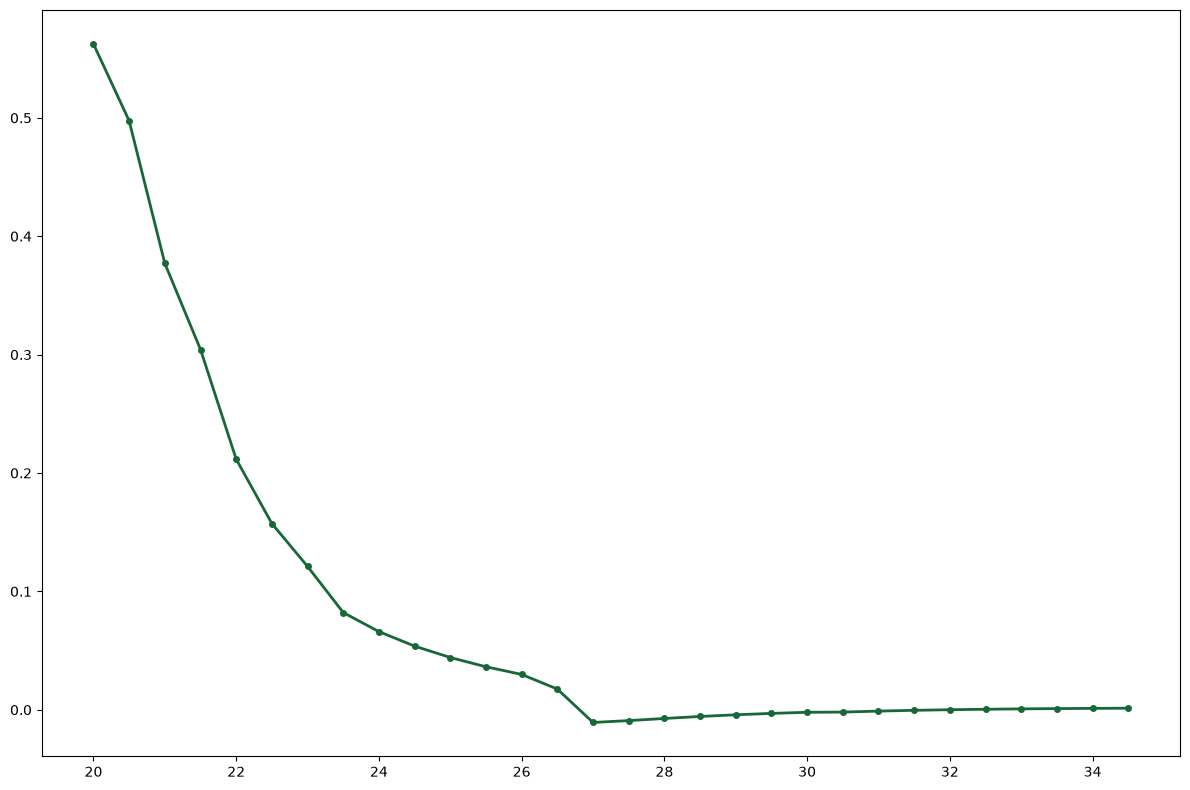

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

plt.plot(
    np.array(radius_data["radius"]) * 1e6,
    np.array(radius_data["loss"]),
    marker="o",
    markersize=4,
    linestyle="-",
    linewidth=2,
)


plt.tight_layout()
plt.show()